In [2]:
import numpy as np

In [3]:
v = np.array([3,4])

In [4]:
print(v)

[3 4]


In [5]:
print(type(v))

<class 'numpy.ndarray'>


In [6]:
w = np.array([1, 2])

# Vector Addition

In [7]:
print(v + w)

[4 6]


# Scalar multiplication

In [8]:
print(w)

[1 2]


In [9]:
print(v*2)

[6 8]


# dot product

In [10]:
dot = np.dot(v, w)

In [11]:
print(dot)

11


# vector magnitude (length)

In [12]:
length = np.linalg.norm(v)

In [13]:
print(length)

5.0


In [14]:
A = np.array([[1, 2], [3, 4]])

In [15]:
print(A)

[[1 2]
 [3 4]]


In [16]:
print(A.shape)

(2, 2)


# matrix multiplication

In [17]:
B = np.array([[5, 6], [7, 8]])

In [18]:
result = np.matmul(A, B)

In [19]:
print(result)

[[19 22]
 [43 50]]


#### matrix multiplication is just many dot products organized into a grid.

#### When a neural network processes a batch of inputs, it's literally doing inputs @ weights — one matrix multiplication, applying the same dot-product logic to every data point in the batch simultaneously. That's why GPUs are good at ML — they're built to do thousands of these multiplications in parallel.

### identity and transpose matrix

In [20]:
I = np.eye(2)

In [21]:
print(I)

[[1. 0.]
 [0. 1.]]


In [22]:
print(A.T)

[[1 3]
 [2 4]]


##### np.eye(2) gives the identity matrix — [[1,0],[0,1]]. Think of it like the number "1" but for matrices: multiply anything by it and you get the same thing back. It shows up in ML for things like resetting weights or solving systems of equations.
A.T is the transpose — rows become columns. Your [[1,2],[3,4]] became [[1,3],[2,4]]. This is everywhere in ML code — you'll see .T constantly when reshaping data to match what a model expects, or in the math behind backpropagation.
That's a genuinely solid first session: vectors, addition, scalar multiplication, dot product, magnitude, matrices, matrix multiplication, identity matrix, transpose — with actual intuition behind every one, not just syntax memorized.

#### Mean, Variance, and Standard Deviation 

In [24]:
import numpy as np

In [25]:
scores = np.array([70, 80, 90, 85, 75])

In [26]:
print(scores)

[70 80 90 85 75]


In [27]:
mean = np.mean(scores)
variance = np.var(scores)
std = np.std(scores)

In [30]:
print(f"Mean: {mean}")
print(f"Variance: {variance}")
print(f"Std Dev: {std}")

Mean: 80.0
Variance: 50.0
Std Dev: 7.0710678118654755


In [31]:
distances = scores - mean
squared = distances ** 2

In [32]:
print(distances)
print(squared)
print(np.mean(squared))

[-10.   0.  10.   5.  -5.]
[100.   0. 100.  25.  25.]
50.0


Variance = how spread out your data is from the mean.
Small variance → scores are clustered close to 80.
Large variance → scores are scattered far from 80.
The reason we square the distances is so that negative distances (scores below 80) don't cancel out positive ones (scores above 80). We want all distances to count positively.
Std Dev is just variance back in the original units — since we squared the distances, the units got squared too. Taking the square root brings it back. So std dev of 7.07 means: on average, scores are about 7 points away from the mean.
That's it. Variance and std dev measure the same thing — spread — just in different scales.
Why this matters for ML: before feeding data into a model, features with huge variance (like salary: 50,000–200,000) will dominate features with small variance (like age: 20–60). So you normalize everything — subtract mean, divide by std — to put all features on equal footing.

variance = Σ(x - mean)² / n

std_dev = √variance

The relationship:
They measure the same thing — spread — but in different units:

Variance is in squared units (exam points²) — hard to interpret intuitively
Std dev is in original units (exam points) — easy to interpret: "scores are typically 7 points from the mean"

So you calculate variance first, then take the square root to get std dev back into units humans can understand.

In [33]:
normalized = (scores - mean) / std

In [34]:
print(f"Original: {scores}")
print(f"Normalized: {normalized}")
print(f"New mean: {np.mean(normalized):.4f}")
print(f"New std: {np.std(normalized):.4f}")

Original: [70 80 90 85 75]
Normalized: [-1.41421356  0.          1.41421356  0.70710678 -0.70710678]
New mean: 0.0000
New std: 1.0000


This is called standardization — after this transformation, every feature has mean=0 and std=1, regardless of original scale. A salary feature (50,000–200,000) and an age feature (20–60) both end up on the same scale — so neither dominates the model unfairly.

Quick summary:

Mean — center of data, best single guess

Variance — average squared distance from mean

Std Dev — square root of variance, same units as data

Standardization — subtract mean, divide by std → mean=0, std=1, puts all features on equal footing

#### Distributions — specifically the normal distribution, which shows up everywhere in ML (error distributions, weight initialization, noise modeling).

In [35]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [36]:
samples = np.random.randn(1000)

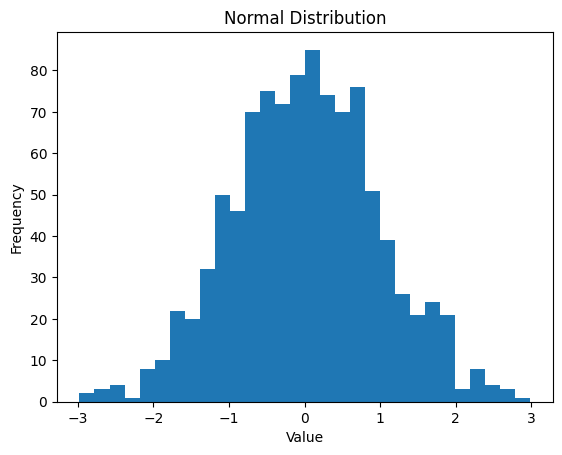

In [37]:
plt.hist(samples, bins=30)
plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

The shape is actually a bell curve (normal distribution). With 1000 samples it's not perfectly smooth, but the peak in the middle and tapering on both sides is exactly right.

####
np.random.randn(1000) — generates 1000 random numbers from a standard normal distribution (mean=0, std=1). You already know what that means now.
plt.hist(samples, bins=30) — draws a histogram:

samples — the data to plot
bins=30 — divides the x-axis into 30 buckets, counts how many values fall in each bucket, draws a bar for each. More bins = more detail but noisier. Fewer bins = smoother but less detail.

plt.title(...) — adds a title to the chart.
plt.xlabel(...) / plt.ylabel(...) — labels the x and y axes.
plt.show() — actually renders and displays the plot. Without this, nothing shows up.
Why normal distribution matters for ML:

Errors in predictions tend to follow it.
Neural network weights are often initialized from it.
Many ML algorithms assume your data is roughly normally distributed

In [39]:
from scipy import stats

In [40]:
x = np.linspace(-4, 4, 100)
y = stats.norm.pdf(x, 0, 1)

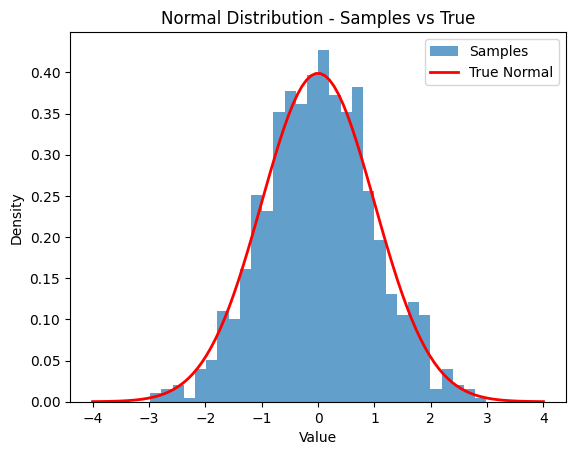

In [41]:
plt.hist(samples, bins=30, density=True, alpha=0.7, label="Samples")
plt.plot(x, y, color='red', linewidth=2, label="True Normal")
plt.title("Normal Distribution - Samples vs True")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

explaining the new parameters:

density=True — scales the histogram so area = 1 (converts frequency to probability density), so it's comparable to the theoretical curve
alpha=0.7 — makes the histogram slightly transparent (0=invisible, 1=solid) so you can see the red line behind it
plt.plot(x, y) — draws the smooth theoretical bell curve in red
plt.legend() — shows the label key for both lines

Great — that red line is the theoretical perfect bell curve, and your histogram of 1000 random samples is hugging it closely. That's the normal distribution in action.
Notice:

Peak at 0 — most values cluster around the mean
Tails taper off symmetrically — extreme values are rare but possible
Your samples approximate the true curve well — 1000 points is enough to see the shape clearly

One important thing to internalize: in ML, you want your model's errors to look like this. If you plot actual - predicted for a well-trained model and it looks like this bell curve centered at 0, your model is doing well — errors are random, small, and unbiased. If the distribution is skewed or has a weird shape, something is wrong with the model.

np.linspace — generates evenly spaced numbers between two points. You'll see it constantly for plotting.
stats.norm.pdf — gives the theoretical probability at each point on a normal curve
density=True — scales histogram to probability

**What is a normal distribution?**

It's a pattern that data naturally falls into when many independent random factors influence the outcome.

Classic example: human height. Your height is influenced by hundreds of genes, nutrition, environment — all independent factors adding up. The result? Most people cluster around the average (say 5'9"), fewer people are very tall or very short, and the further you go from the average in either direction, the rarer it gets.

That pattern — **peak in the middle, tapering symmetrically on both sides** — is the normal distribution. Also called the bell curve.

Mathematically it's defined by just two numbers:
- **Mean (μ)** — where the peak is, the center
- **Std Dev (σ)** — how wide or narrow the bell is. Small std dev = tall narrow bell (data clustered tightly). Large std dev = short wide bell (data spread out).

**The 68-95-99.7 rule** — worth knowing:
- 68% of data falls within 1 std dev of the mean
- 95% within 2 std devs
- 99.7% within 3 std devs

So for exam scores with mean=80, std=7: 95% of students scored between 66 and 94.

**Why it matters for ML:**

First, **errors follow it.** When your model makes prediction errors, they tend to be normally distributed — small errors are common, large errors are rare. This assumption is baked into linear regression mathematically.

Second, **weight initialization.** When you start training a neural network, you initialize weights randomly from a normal distribution — not too big, not too small, centered at zero.

Third, **the Central Limit Theorem** — one of the most powerful ideas in statistics. It says: take any data, compute averages of random samples, and those averages will be normally distributed regardless of what the original data looked like. This is why normal distribution assumptions hold even when your raw data isn't perfectly normal.

Fourth, **anomaly detection.** If your data is normally distributed, anything beyond 3 std devs from the mean is extremely rare (0.3% chance). So you flag it as an anomaly — useful in fraud detection, which is directly relevant to your finance background.

Short version: **normal distribution is nature's default pattern, and ML is built on top of that assumption in dozens of ways.**

Simple arithmetic using the 68-95-99.7 rule.

95% of data falls within **2 std devs** of the mean in either direction.

So:
- Mean = 80
- Std dev = 7

**Lower bound** = mean − (2 × std dev) = 80 − 14 = **66**

**Upper bound** = mean + (2 × std dev) = 80 + 14 = **94**

So 95% of students scored between 66 and 94. Only 5% scored below 66 or above 94 — those are the outliers on either tail of the bell curve.

You can apply this to any normal distribution:

| Range | Coverage |
|-------|----------|
| mean ± 1 std dev | 68% of data |
| mean ± 2 std devs | 95% of data |
| mean ± 3 std devs | 99.7% of data |

So for your scores with mean=80, std=7:
- 68% scored between **73 and 87**
- 95% scored between **66 and 94**
- 99.7% scored between **59 and 101**

This is one of those rules worth memorizing — you'll use it instinctively when looking at data to quickly spot outliers and understand spread.

In [43]:
mean = np.mean(samples)
std = np.std(samples)

In [44]:
within_1 = np.sum((samples >= mean - std) & (samples <= mean + std)) / len(samples) * 100
within_2 = np.sum((samples >= mean - 2*std) & (samples <= mean + 2*std)) / len(samples) * 100
within_3 = np.sum((samples >= mean - 3*std) & (samples <= mean + 3*std)) / len(samples) * 100
